# Sampling the question space
Run with the `wiscs-questions` environment. Exact duplicate lines are collapsed (first occurrence retained); paraphrases remain distinct. Model downloads happen on first execution. Llama requires approved Hugging Face access and a local login (`hf auth login`) or `HF_TOKEN`. CPU float32 Llama weights alone need about 32 GB RAM; accelerator float16 weights need about 16 GB, plus runtime memory.

GPT-2 and Llama use the mean of final-layer content-token states (padding and added special tokens excluded), followed by L2 normalization. The Sentence Transformer uses its trained pooling pipeline and L2 normalization. Questions are passed as plain text, without chat templates. No truncation is allowed.


In [7]:
import csv
from pathlib import Path
import numpy as np
from question_sampling import (
    MODELS, read_questions, save_embeddings, cosine_similarity,
    representational_similarity, farthest_point_sampling,
)

N = 50  # Number of questions to select.
SEED = 0
SAMPLING_MODEL = "sentence_transformer"  # Or "gpt2" / "llama".
BATCH_SIZE = 8  # Reduce if accelerator memory is limited.
OUTPUT = Path("outputs")
questions, line_numbers = read_questions()
print(f"{len(questions)} unique questions")


219 unique questions


In [8]:
# Each completed model is saved immediately; reruns reuse matching NPZ files.
embeddings = {}
for name in MODELS:
    print(name, MODELS[name])
    embeddings[name] = save_embeddings(
        name, questions, line_numbers, output_dir=OUTPUT, batch_size=BATCH_SIZE,
    )


sentence_transformer sentence-transformers/all-MiniLM-L6-v2
gpt2 openai-community/gpt2
llama meta-llama/Llama-3.2-3B


## Representational similarity
Compare only the strict upper triangle of each cosine similarity matrix: each question pair occurs once, and self-similarities are excluded. Rho describes agreement; ordinary Spearman p-values are omitted because question pairs are dependent. High agreement does not by itself validate semantic coverage.


In [9]:
similarities = {name: cosine_similarity(values) for name, values in embeddings.items()}
rho = representational_similarity(similarities)
print(list(similarities))
print(np.round(rho, 3))
np.savez_compressed(OUTPUT / "representational_similarity.npz",
                    model_names=np.array(list(similarities)), spearman_rho=rho,
                    **similarities)


['sentence_transformer', 'gpt2', 'llama']
[[1.    0.244 0.404]
 [0.244 1.    0.462]
 [0.404 0.462 1.   ]]


## Cosine distance matrices
Cosine distance is `1 - cosine similarity`. All plots share a 0–2 color scale and question order. Axes show only zero and the last zero-based question index; compact colorbars show only 0 and 2. Each plot is saved as SVG in `outputs/`.


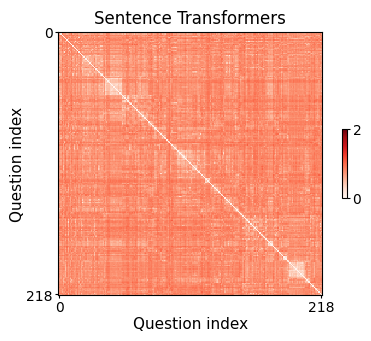

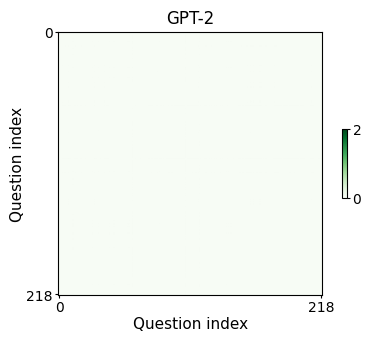

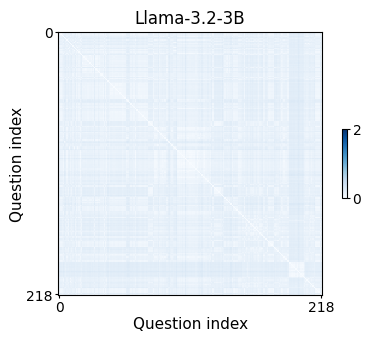

In [15]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator

colormaps = {"gpt2": "Greens", "llama": "Blues", "sentence_transformer": "Reds"}
titles = {"gpt2": "GPT-2", "llama": MODELS["llama"].split("/")[-1],
          "sentence_transformer": "Sentence Transformers"}
for name, similarity in similarities.items():
    distance = np.clip(1 - similarity, 0, 2)
    np.fill_diagonal(distance, 0)
    fig, ax = plt.subplots(figsize=(3.6, 3.3), layout="constrained")
    image = ax.imshow(distance, cmap=colormaps[name], vmin=0, vmax=2,
                      interpolation="nearest")
    endpoints = [0, len(distance) - 1]
    ax.set(xlabel="Question index", ylabel="Question index",
           xticks=endpoints, yticks=endpoints)
    ax.set_title(titles[name], fontsize=12, pad=6)
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)
    ax.xaxis.labelpad = 1
    ax.yaxis.labelpad = 1
    ax.tick_params(axis="both", labelsize=10, length=2, pad=2)
    ax.xaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_minor_locator(NullLocator())
    colorbar = fig.colorbar(image, ax=ax, shrink=0.25, aspect=15,
                           pad=0.03, ticks=[0, 2])
    colorbar.minorticks_off()
    colorbar.ax.tick_params(labelsize=10, length=2, pad=2)
    fig.savefig(OUTPUT / f"{name}_cosine_distance.svg",
                bbox_inches="tight", pad_inches=0.04)
    plt.show()
    plt.close(fig)


## Farthest point sampling
This follows the [PyVista NumPy example](https://docs.pyvista.org/examples/01-filter/farthest_point_sampling.html), applied to all embedding dimensions. On unit vectors, squared Euclidean distance equals twice cosine distance, so both produce the same greedy choices. The seed fixes the initial question; ties follow input order. FPS favors coverage, including outliers, and should be followed by stimulus review. Choose the sampling model above after inspecting agreement. MDS, if added later, should be used for visualization; sampling uses the original space.


In [11]:
selected = farthest_point_sampling(embeddings[SAMPLING_MODEL], N, seed=SEED)
stem = f"sample_{SAMPLING_MODEL}_n{N}_seed{SEED}"
with (OUTPUT / f"{stem}.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["selection_order", "question_index", "source_line", "question"])
    writer.writerows((order, int(i), int(line_numbers[i]), questions[i])
                    for order, i in enumerate(selected, 1))
(OUTPUT / f"{stem}.txt").write_text("\n".join(questions[selected]) + "\n")
print("\n".join(questions[selected]))


Is it used during meals?
Does it come in pairs?
Does it live above ground?
Would you miss it if it were gone?
Can it bend?
Is it clear?
Is it a person?
Is its job to make sounds?
Is it hard to catch?
Can you buy it?
Does it have feelings?
Was it around 100 years ago?
Is it part of something larger?
Can you ride on/in it?
Does it have wires or a cord?
Can it be washed?
Does it have at least one hole?
Does it cast a shadow?
Are there many varieties of it?
Does it provide protection?
Is it warm blooded?
Is it smart?
Is it pointed/sharp?
Is it made of metal?
Does it contain liquid?
Can it bite or sting?
Can it be easily moved?
Does it have a backbone?
Is it always the same color(s)?
Does it have writing on it?
Do you interact with it?
Is it scary?
Is it used to carry things?
Does it smell good?
Is it usually inside?
Does it have horns/thorns/spikes?
Does it roll?
Is it slippery?
Does it have four legs?
Does it have corners?
Does it have feathers?
Is it nocturnal?
Can it dig?
Can it run?
Is

## Sentence Transformers MDS
Fit metric MDS directly to the precomputed cosine distances, with two dimensions and four seeded initializations. These are coordinates of a jointly fitted 2D representation, not variance-ranked components. Orientation is arbitrary and distances are approximate; Stress-1 reports distortion (lower is better). Sampling still uses the full embedding space. Save the plot as SVG and coordinates, question identities, and stress as NPZ.

Black circles mark the questions selected by FPS using `SAMPLING_MODEL`, `N`, and `SEED` above.


2D MDS Stress-1: 0.383


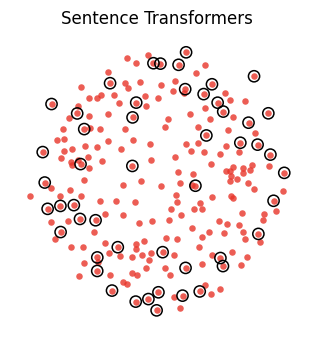

In [16]:
from sklearn.manifold import MDS
import matplotlib.pyplot as plt

st_distance = np.clip(1 - similarities["sentence_transformer"], 0, 2)
np.fill_diagonal(st_distance, 0)
mds = MDS(n_components=2, metric=True, dissimilarity="precomputed",
          random_state=SEED, n_init=4, max_iter=1000, eps=1e-6,
          normalized_stress=False)
coordinates = mds.fit_transform(st_distance)
fitted_distances = np.linalg.norm(coordinates[:, None] - coordinates[None, :], axis=2)
stress1 = np.sqrt(mds.stress_ / np.sum(np.triu(fitted_distances ** 2, k=1)))
print(f"2D MDS Stress-1: {stress1:.3f}")
np.savez_compressed(OUTPUT / "sentence_transformer_mds.npz",
                    coordinates=coordinates, questions=questions,
                    line_numbers=line_numbers, stress1=stress1, raw_stress=mds.stress_, seed=SEED)

# Recompute the same deterministic FPS selection when running this cell on its own.
selected = farthest_point_sampling(embeddings[SAMPLING_MODEL], N, seed=SEED)

fig, ax = plt.subplots(figsize=(3.6, 3.3), layout="constrained")
ax.scatter(coordinates[:, 0], coordinates[:, 1], s=22,
           color=plt.get_cmap("Reds")(0.65), alpha=0.8, linewidths=0)
ax.scatter(coordinates[selected, 0], coordinates[selected, 1], s=65,
           facecolors="none", edgecolors="black", linewidths=1.1, zorder=3)
ax.set_title("Sentence Transformers", fontsize=12, pad=6)
ax.set(xticks=[], yticks=[],
       xlabel="", ylabel="")
ax.minorticks_off()
ax.set_aspect("equal", adjustable="box")
ax.spines[:].set_visible(False)
ax.margins(0.08)
fig.savefig(OUTPUT / "sentence_transformer_mds.svg",
            bbox_inches="tight", pad_inches=0.04)
plt.show()
plt.close(fig)
